In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#### Loading the Dataset (Bank Marketing Dataset)

In [2]:
df=pd.read_csv(r"D:\BITS WILP\BITS WILP COURSE\SEM1\MACHINE LEARNING\ASSIGNMENT\bank.csv",sep=';')
df=pd.DataFrame(df)
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


#### Dataset Analysis

In [3]:
# Examining the shape of the dataset.
df.shape

(4521, 17)

##### Thus the dataset meets the criterion in the question of Minimum Feature Size: 12 Minimum Instance Size: 500.

In [4]:
# Examining the different features and checking the values within each column

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


##### All are non-null columns.  There are 7 int columns and  object columns

In [5]:
df['y'].value_counts(dropna=False)

y
no     4000
yes     521
Name: count, dtype: int64

##### There is class imbalance in the output column with no-4000 and yes only 521.  Also one important decision is we will need to encode the no and yes to 0 and 1 for further analysis in subsequent steps and at the same time while grouping we need to handle class imbalance.

#### Data Separation and Processing

In [6]:
## Spliting the input features and the output features

X=df.drop(['y'],axis=1)
Y=(df['y']=='yes').astype(int)

In [7]:
X.shape

(4521, 16)

In [8]:
Y.shape

(4521,)

In [9]:
X.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown


In [10]:
# Splitting of X and Y in 80-20 ratio. 
from sklearn.model_selection import train_test_split

xtrain,xtest,ytrain,ytest=train_test_split(X,Y,test_size=0.20,random_state=42,stratify=Y)

In [11]:
#Creating the test dataframe
test_df=xtest.copy()
test_df['y']=ytest.values

In [12]:
test_df.shape

(905, 17)

In [13]:
# Exporting the test_dataset created above into a test_dataset.csv file
test_df.to_csv('test_data.csv',index=False)

#### Feature Scaling and Encoding of Categorical Columns

In [14]:
#Importing the required libraries
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [15]:
#Identifying both the numerical columns and categorical columns respectively and storing them respectively.
num_cols=xtrain.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols=xtrain.select_dtypes(include=['object']).columns.tolist()

#Printing the no. of numerical and categorical columns\

print(f"Numerical Features ({len(num_cols)}):{num_cols}")
print(f"Categorical Features ({len(cat_cols)}):{cat_cols}")


Numerical Features (7):['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical Features (9):['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [16]:
# Scaling the numerical columns using the Standard Scalar for the numerical columns and at the sametime using One-Hot Encoding for categorical columns.

# Define the ColumnTransformer

preprocessor= ColumnTransformer(transformers=[('num', StandardScaler(),num_cols),('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False), cat_cols)])

# Fit the xtrain dataset on it

xtrain_transformed=preprocessor.fit_transform(xtrain)
print("Transformed xtrain shape:",xtrain_transformed.shape)



Transformed xtrain shape: (3616, 51)


In [17]:
xtrain_transformed

array([[-0.86434735, -0.5058649 , -0.49244386, ...,  0.        ,
         0.        ,  1.        ],
       [-0.67320403, -0.44823206, -0.24871583, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.28251258, -0.49946125,  0.72619629, ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [-0.57763237, -0.49946125, -0.24871583, ...,  0.        ,
         0.        ,  1.        ],
       [-0.38648905, -0.46210663,  0.11687622, ...,  0.        ,
         0.        ,  1.        ],
       [-0.67320403,  0.17541213,  0.36060425, ...,  0.        ,
         0.        ,  1.        ]], shape=(3616, 51))

##### Thus, now we have xtrain with numerical columns which are scaled using the Standard Scalar and all the categorical columns are encoded using the One Hot Encoder. 

#### IMPLEMENTING THE MODELS AND THE EVALUATION METRICS

##### (I) LOGISTIC REGRESSION

In [18]:
# Implementing the Logistic Regression Model

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_pipe=Pipeline([('preprocessor',preprocessor),('classifier',LogisticRegression(max_iter=1000,random_state=42,class_weight='balanced'))])
#To handle the class imbalance we have class_weight=balanced


In [19]:
# We have created the pipeline function that first comprises of handing the Standard Scaler and the One Hot Encoder and secondly we go ahead with Logistic Regression.
lr_pipe.fit(xtrain,ytrain)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [20]:
# Prediction based on the Logistic Regression

# 1) Predicting class labels
y_predict_logr=lr_pipe.predict(xtest)

# 2) Predicting probability of class 1 ("YES")

y_proba_logr=lr_pipe.predict_proba(xtest)[:,1]

# Inspect the first 5 predictions vs their probabilities

print("First 5 class predictions:",y_predict_logr[:5])
print("First 5 possitive probabilities :",y_proba_logr[:5])

First 5 class predictions: [1 0 0 0 0]
First 5 possitive probabilities : [0.6686609  0.06318226 0.10928014 0.04351764 0.07778633]


In [21]:
#Computing the Performance Metrics for Logistic Regression

from sklearn.metrics import (accuracy_score,roc_auc_score,precision_score,recall_score,f1_score,matthews_corrcoef, confusion_matrix)

acc_log=accuracy_score(ytest,y_predict_logr)
auc_log=roc_auc_score(ytest,y_proba_logr)
precision_score_log=precision_score(ytest,y_predict_logr,zero_division=0)
rec_log=recall_score(ytest,y_predict_logr,zero_division=0)
f1_log=f1_score(ytest,y_predict_logr,zero_division=0)
mcc_log=matthews_corrcoef(ytest,y_predict_logr)

print("---------LOGISTIC REGRESSION EVALUATION METRICS--------")
print("1. Accuracy:",acc_log)
print("2. AUC Score:",auc_log)
print("3. Precision:",precision_score_log)
print("4. Recall:",rec_log)
print("5. F1 Score:",f1_log)
print("6. MCC Score:",mcc_log)

print("Confusion Matrix [[TN,FP],[FN,TP]] :")
print(confusion_matrix(ytest,y_predict_logr))

---------LOGISTIC REGRESSION EVALUATION METRICS--------
1. Accuracy: 0.8232044198895028
2. AUC Score: 0.8908095649668683
3. Precision: 0.37155963302752293
4. Recall: 0.7788461538461539
5. F1 Score: 0.5031055900621118
6. MCC Score: 0.45330876556514516
Confusion Matrix [[TN,FP],[FN,TP]] :
[[664 137]
 [ 23  81]]


##### (II) DECISION TREE CLASSIFIER

In [22]:
# Implementing the Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

dt_pipe=Pipeline([('preprocessor',preprocessor),('classifier',DecisionTreeClassifier(max_depth=5,random_state=42,class_weight='balanced'))])
#To handle the class imbalance we have class_weight=balanced


In [23]:
# We have created the pipeline function that first comprises of handing the Standard Scaler and the One Hot Encoder and secondly we go ahead with Decision Tree Classifier.
dt_pipe.fit(xtrain,ytrain)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [24]:
# Prediction based on the Decision Tree Classifier

# 1) Predicting class labels
y_predict_dtc=dt_pipe.predict(xtest)

# 2) Predicting probability of class 1 ("YES")

y_proba_dtc=dt_pipe.predict_proba(xtest)[:,1]

# Inspect the first 5 predictions vs their probabilities

print("First 5 class predictions:",y_predict_dtc[:5])
print("First 5 possitive probabilities :",y_proba_dtc[:5])

First 5 class predictions: [1 1 0 0 0]
First 5 possitive probabilities : [0.65977768 0.53194762 0.11263514 0.11263514 0.11263514]


In [25]:
#Computing the Performance Metrics for Decision Tree Classifier

acc_dtc=accuracy_score(ytest,y_predict_dtc)
auc_dtc=roc_auc_score(ytest,y_proba_dtc)
precision_score_dtc=precision_score(ytest,y_predict_dtc,zero_division=0)
rec_dtc=recall_score(ytest,y_predict_dtc,zero_division=0)
f1_dtc=f1_score(ytest,y_predict_dtc,zero_division=0)
mcc_dtc=matthews_corrcoef(ytest,y_predict_dtc)

print("---------DECISION TREE CLASSIFIER EVALUATION METRICS--------")
print("1. Accuracy:",acc_dtc)
print("2. AUC Score:",auc_dtc)
print("3. Precision:",precision_score_dtc)
print("4. Recall:",rec_dtc)
print("5. F1 Score:",f1_dtc)
print("6. MCC Score:",mcc_dtc)

print("Confusion Matrix [[TN,FP],[FN,TP]] :")
print(confusion_matrix(ytest,y_predict_dtc))

---------DECISION TREE CLASSIFIER EVALUATION METRICS--------
1. Accuracy: 0.7602209944751381
2. AUC Score: 0.8193664169787764
3. Precision: 0.30584192439862545
4. Recall: 0.8557692307692307
5. F1 Score: 0.4506329113924051
6. MCC Score: 0.4121357598818966
Confusion Matrix [[TN,FP],[FN,TP]] :
[[599 202]
 [ 15  89]]


##### (III) K-Nearest Neighbor (KNN) Classifier

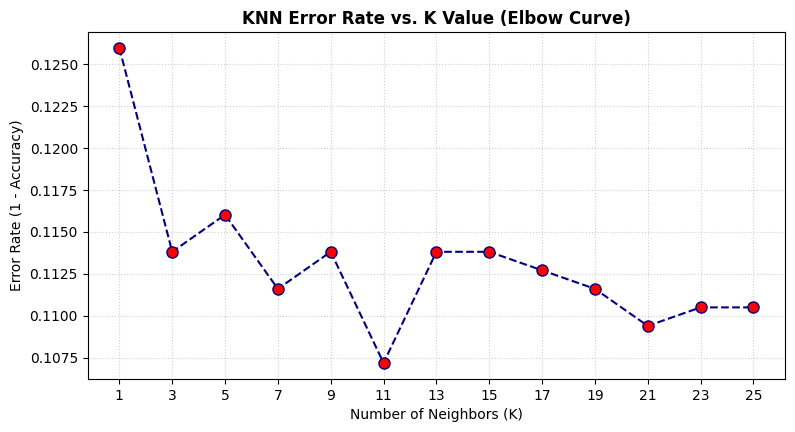

In [26]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

xtest_transformed = preprocessor.transform(xtest)

# Range of odd K values to test
k_values = range(1, 27, 2)
error_rates = []

# Loop through each K and calculate error rate on test data
for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(xtrain_transformed, ytrain)
    pred_k = knn_temp.predict(xtest_transformed)
    # Error rate = percentage of wrong predictions (1 - Accuracy)
    error_rates.append(1.0 - accuracy_score(ytest, pred_k))

# Plot the Elbow Curve
plt.figure(figsize=(9, 4.5))
plt.plot(k_values, error_rates, color='navy', linestyle='--', marker='o', markerfacecolor='red', markersize=8)
plt.title('KNN Error Rate vs. K Value (Elbow Curve)', fontsize=12, fontweight='bold')
plt.xlabel('Number of Neighbors (K)', fontsize=10)
plt.ylabel('Error Rate (1 - Accuracy)', fontsize=10)
plt.xticks(list(k_values))
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [27]:


knn_pipe=Pipeline([('preprocessor',preprocessor),('classifier',KNeighborsClassifier(n_neighbors=7))])


In [28]:
# We have created the pipeline function that first comprises of handing the Standard Scaler and the One Hot Encoder and secondly we go ahead with K-Nearest Neighbor(KNN) Classifier.
knn_pipe.fit(xtrain,ytrain)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [29]:
# Prediction based on the K-Neighbour Classifier

# 1) Predicting class labels
y_predict_knn=knn_pipe.predict(xtest)

# 2) Predicting probability of class 1 ("YES")

y_proba_knn=knn_pipe.predict_proba(xtest)[:,1]

# Inspect the first 5 predictions vs their probabilities

print("First 5 class predictions:",y_predict_knn[:5])
print("First 5 possitive probabilities :",y_proba_knn[:5])

First 5 class predictions: [0 0 0 0 0]
First 5 possitive probabilities : [0.14285714 0.         0.         0.         0.        ]


In [30]:
#Computing the Performance Metrics for K Neighbour Classifier

acc_knn=accuracy_score(ytest,y_predict_knn)
auc_knn=roc_auc_score(ytest,y_proba_knn)
precision_score_knn=precision_score(ytest,y_predict_knn,zero_division=0)
rec_knn=recall_score(ytest,y_predict_knn,zero_division=0)
f1_knn=f1_score(ytest,y_predict_knn,zero_division=0)
mcc_knn=matthews_corrcoef(ytest,y_predict_knn)

print("-------K NEIGHBOUR CLASSIFIER EVALUATION METRICS--------")
print("1. Accuracy:",acc_knn)
print("2. AUC Score:",auc_knn)
print("3. Precision:",precision_score_knn)
print("4. Recall:",rec_knn)
print("5. F1 Score:",f1_knn)
print("6. MCC Score:",mcc_knn)

print("Confusion Matrix [[TN,FP],[FN,TP]] :")
print(confusion_matrix(ytest,y_predict_knn))

-------K NEIGHBOUR CLASSIFIER EVALUATION METRICS--------
1. Accuracy: 0.8883977900552487
2. AUC Score: 0.7997215019686931
3. Precision: 0.5517241379310345
4. Recall: 0.15384615384615385
5. F1 Score: 0.24060150375939848
6. MCC Score: 0.2492023868516592
Confusion Matrix [[TN,FP],[FN,TP]] :
[[788  13]
 [ 88  16]]


##### (IV) NAIVE BAYES CLASSIFIER (GAUSSIAN)

In [31]:
from sklearn.naive_bayes import GaussianNB

nb_pipe=Pipeline([('preprocessor',preprocessor),('classifier',GaussianNB())])


# Fit on training data

nb_pipe.fit(xtrain,ytrain)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [32]:
# Prediction based on the Naive Bayes Classifier (Gaussian)

# 1) Predicting class labels
y_predict_nb=nb_pipe.predict(xtest)

# 2) Predicting probability of class 1 ("YES")

y_proba_nb=nb_pipe.predict_proba(xtest)[:,1]

# Inspect the first 5 predictions vs their probabilities

print("First 5 class predictions:",y_predict_nb[:5])
print("First 5 possitive probabilities :",y_proba_nb[:5])

First 5 class predictions: [0 0 0 0 0]
First 5 possitive probabilities : [1.98895435e-01 1.16018051e-16 8.27361905e-03 3.65533092e-07
 4.01402523e-06]


In [33]:
#Computing the Performance Metrics for Naive Bayes Classifier (Gaussian)

acc_nb=accuracy_score(ytest,y_predict_nb)
auc_nb=roc_auc_score(ytest,y_proba_nb)
precision_score_nb=precision_score(ytest,y_predict_nb,zero_division=0)
rec_nb=recall_score(ytest,y_predict_nb,zero_division=0)
f1_nb=f1_score(ytest,y_predict_nb,zero_division=0)
mcc_nb=matthews_corrcoef(ytest,y_predict_nb)

print("-------NAIVE BAYES CLASSIFIER EVALUATION METRICS--------")
print("1. Accuracy:",acc_nb)
print("2. AUC Score:",auc_nb)
print("3. Precision:",precision_score_nb)
print("4. Recall:",rec_nb)
print("5. F1 Score:",f1_nb)
print("6. MCC Score:",mcc_nb)

print("Confusion Matrix [[TN,FP],[FN,TP]] :")
print(confusion_matrix(ytest,y_predict_nb))

-------NAIVE BAYES CLASSIFIER EVALUATION METRICS--------
1. Accuracy: 0.8209944751381215
2. AUC Score: 0.7880954095841736
3. Precision: 0.3092105263157895
4. Recall: 0.4519230769230769
5. F1 Score: 0.3671875
6. MCC Score: 0.27371462552187215
Confusion Matrix [[TN,FP],[FN,TP]] :
[[696 105]
 [ 57  47]]


##### (IV) Support Vector Machines

In [34]:
from sklearn.svm import SVC

svc_pipe=Pipeline([('preprocessor',preprocessor),('classifier',SVC(kernel='rbf',probability=True, random_state=42,class_weight='balanced'))])


# Fit on training data

svc_pipe.fit(xtrain,ytrain)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [35]:
# Prediction based on the SVC 

# 1) Predicting class labels
y_predict_svc=svc_pipe.predict(xtest)

# 2) Predicting probability of class 1 ("YES")

y_proba_svc=svc_pipe.predict_proba(xtest)[:,1]

# Inspect the first 5 predictions vs their probabilities

print("First 5 class predictions:",y_predict_svc[:5])
print("First 5 possitive probabilities :",y_proba_svc[:5])

First 5 class predictions: [1 0 0 0 0]
First 5 possitive probabilities : [0.18656855 0.03325655 0.0079481  0.01941436 0.01083222]


In [36]:
#Computing the Performance Metrics for SVC

acc_svc=accuracy_score(ytest,y_predict_svc)
auc_svc=roc_auc_score(ytest,y_proba_svc)
precision_score_svc=precision_score(ytest,y_predict_svc,zero_division=0)
rec_svc=recall_score(ytest,y_predict_svc,zero_division=0)
f1_svc=f1_score(ytest,y_predict_svc,zero_division=0)
mcc_svc=matthews_corrcoef(ytest,y_predict_svc)

print("-------SUPPORT VECTOR MACHINE (SVC) EVALUATION METRICS--------")
print("1. Accuracy:",acc_svc)
print("2. AUC Score:",auc_svc)
print("3. Precision:",precision_score_svc)
print("4. Recall:",rec_svc)
print("5. F1 Score:",f1_svc)
print("6. MCC Score:",mcc_svc)

print("Confusion Matrix [[TN,FP],[FN,TP]] :")
print(confusion_matrix(ytest,y_predict_svc))

-------SUPPORT VECTOR MACHINE (SVC) EVALUATION METRICS--------
1. Accuracy: 0.8453038674033149
2. AUC Score: 0.9019494862191492
3. Precision: 0.41262135922330095
4. Recall: 0.8173076923076923
5. F1 Score: 0.5483870967741935
6. MCC Score: 0.506752246237032
Confusion Matrix [[TN,FP],[FN,TP]] :
[[680 121]
 [ 19  85]]


#### COMPARISON OF THE DIFFERENT MODELS

In [37]:
import pandas as pd

# Assembling the master comparison table with your exact variables
comparison_table = pd.DataFrame([
    {
        "ML Model Name": "Logistic Regression",
        "Accuracy": round(acc_log, 4),
        "AUC": round(auc_log, 4),
        "Precision": round(precision_score_log, 4),
        "Recall": round(rec_log, 4),
        "F1": round(f1_log, 4),
        "MCC": round(mcc_log, 4)
    },
    {
        "ML Model Name": "Decision Tree",
        "Accuracy": round(acc_dtc, 4),
        "AUC": round(auc_dtc, 4),
        "Precision": round(precision_score_dtc, 4),
        "Recall": round(rec_dtc, 4),
        "F1": round(f1_dtc, 4),
        "MCC": round(mcc_dtc, 4)
    },
    {
        "ML Model Name": "KNN",
        "Accuracy": round(acc_knn, 4),
        "AUC": round(auc_knn, 4),
        "Precision": round(precision_score_knn, 4),
        "Recall": round(rec_knn, 4),
        "F1": round(f1_knn, 4),
        "MCC": round(mcc_knn, 4)
    },
    {
        "ML Model Name": "Naive Bayes",
        "Accuracy": round(acc_nb, 4),
        "AUC": round(auc_nb, 4),
        "Precision": round(precision_score_nb, 4),
        "Recall": round(rec_nb, 4),
        "F1": round(f1_nb, 4),
        "MCC": round(mcc_nb, 4)
    },
    {
        "ML Model Name": "Support Vector Machine",
        "Accuracy": round(acc_svc, 4),
        "AUC": round(auc_svc, 4),
        "Precision": round(precision_score_svc, 4),
        "Recall": round(rec_svc, 4),
        "F1": round(f1_svc, 4),
        "MCC": round(mcc_svc, 4)
    }
])

# Save comparison table to CSV for your README & Streamlit app
import os
os.makedirs('model', exist_ok=True)
comparison_table.to_csv('model/model_comparison.csv', index=False)

# Display the table
comparison_table

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8232,0.8908,0.3716,0.7788,0.5031,0.4533
1,Decision Tree,0.7602,0.8194,0.3058,0.8558,0.4506,0.4121
2,KNN,0.8884,0.7997,0.5517,0.1538,0.2406,0.2492
3,Naive Bayes,0.8210,0.7881,0.3092,0.4519,0.3672,0.2737
4,Support Vector Machine,0.8453,0.9019,0.4126,0.8173,0.5484,0.5068


##### The highest AUC is of Support Vector Machine. The highest Recall is of Decision Tree Classifiers.  The highest F1 score is of Logistic Regression model.  The highest MCC score is of Support Vector Machines.  

### FINAL OBSERVATION:-

##### According to me the best model based on the above metrics is the Support Vector Machine.  It gives the highest AUC score, also the F1 score is the combination of the precision and recall, Support Vector Machine gives the highest F1 score at the same time.  The MCC score is also highest among all the models.  The Accuracy is moderate, but in a dataset which is so much imbalanced, accuracy alone cannot be considered as a stand alone metric to judge a model performance.

#### SAVING THE 5 TRAINED MODELS

In [38]:
import joblib
import os

# Saving all the five trained models

joblib.dump(lr_pipe,'model/logistic_regression.joblib')
joblib.dump(dt_pipe,'model/decision_tree.joblib')
joblib.dump(knn_pipe,'model/knn.joblib')
joblib.dump(nb_pipe,'model/naive_bayes.joblib')
joblib.dump(svc_pipe,'model/svm.joblib')

print("All 5 Models saved")


All 5 Models saved


### STREAMLIT APP DEVELOPMENT

In [40]:
%%writefile app.py
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# ---------------------------------------------------------
# 1. Page Header (Left-aligned, clean academic layout)
# ---------------------------------------------------------
st.set_page_config(page_title="ML Assignment 2: Classification", layout="wide")

st.title("Machine Learning Assignment 2: Classification Models")
st.caption("Student Project: Bank Marketing Prediction | BITS Pilani WILP - M.Tech (AIML)")
st.divider()

# ---------------------------------------------------------
# 2. Sidebar: Model Selection (Rubric b: 1 Mark)
# ---------------------------------------------------------
st.sidebar.header("1. Model Selection")

models_dict = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

selected_model_name = st.sidebar.selectbox(
    "Choose a model:",
    list(models_dict.keys()),
    index=4  # Default to Support Vector Machine (Overall Winner)
)

# ---------------------------------------------------------
# 3. Sidebar: Dataset Upload Option (Rubric a: 1 Mark)
# ---------------------------------------------------------
st.sidebar.header("2. Dataset Option")
uploaded_file = st.sidebar.file_uploader(
    "Upload Test CSV (must contain input features & 'y' target):", 
    type=["csv"]
)

# ---------------------------------------------------------
# 4. Helper Functions: Caching & Data Loading (No Retraining)
# ---------------------------------------------------------
@st.cache_resource
def load_saved_model(filename):
    model_path = os.path.join("model", filename)
    if os.path.exists(model_path):
        return joblib.load(model_path)
    if os.path.exists(filename):
        return joblib.load(filename)
    return None

def get_test_data():
    if uploaded_file is not None:
        return pd.read_csv(uploaded_file), "Uploaded CSV File"
    else:
        # Check standard locations for saved test file
        possible_paths = [
            os.path.join("model", "test.csv"),
            os.path.join("model", "test_data.csv"),
            "test_data.csv",
            "test.csv"
        ]
        for p in possible_paths:
            if os.path.exists(p):
                return pd.read_csv(p), f"Default Test Data (`{p}`)"
        return None, "None"

# Load the selected model and dataset
selected_file = models_dict[selected_model_name]
model = load_saved_model(selected_file)
df_test, data_source_name = get_test_data()

# ---------------------------------------------------------
# 5. Validation & Inference
# ---------------------------------------------------------
if model is None:
    st.error(f"Error: Model file `{selected_file}` could not be found inside the `model/` directory.")
    st.stop()

if df_test is None:
    st.warning("Please upload a test CSV file or place `test.csv` in the `model/` directory.")
    st.stop()

# Locate target column ('y')
target_col = None
for col in ['y', 'target', 'deposit', 'class']:
    if col in df_test.columns:
        target_col = col
        break

if target_col is None:
    st.error("Error: The test dataset must contain the ground-truth target column ('y').")
    st.stop()

# Separate input features and ground truth
X_test = df_test.drop(columns=[target_col])
y_raw = df_test[target_col]

# Convert target to binary (1 for 'yes', 0 for 'no')
if y_raw.dtype == object:
    y_test = (y_raw.astype(str).str.strip().str.lower() == 'yes').astype(int)
else:
    y_test = y_raw.astype(int)

# Run Inference (No Retraining)
try:
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
except Exception as e:
    st.error(f"Inference error: {e}")
    st.stop()

# ---------------------------------------------------------
# 6. Evaluation Metrics Display (Rubric c: 1 Mark)
# ---------------------------------------------------------
acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba) if y_proba is not None else 0.0
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
mcc = matthews_corrcoef(y_test, y_pred)

st.subheader(f"Evaluation Metrics: {selected_model_name}")
st.write(f"Data Source: **{data_source_name}** ({df_test.shape[0]} samples)")

# 6 Clean Native Streamlit Metric Cards
c1, c2, c3, c4, c5, c6 = st.columns(6)
c1.metric("Accuracy", f"{acc:.4f}")
c2.metric("AUC Score", f"{auc:.4f}")
c3.metric("Precision", f"{prec:.4f}")
c4.metric("Recall", f"{rec:.4f}")
c5.metric("F1 Score", f"{f1:.4f}")
c6.metric("MCC Score", f"{mcc:.4f}")

st.divider()

# ---------------------------------------------------------
# 7. Confusion Matrix & Classification Report (Rubric d: 1 Mark)
# ---------------------------------------------------------
tab1, tab2, tab3 = st.tabs([
    "Confusion Matrix", 
    "Classification Report", 
    "All Models Comparison"
])

with tab1:
    st.subheader("Confusion Matrix")
    cm = confusion_matrix(y_test, y_pred)
    
    col_plot, col_info = st.columns([1, 1.2])
    with col_plot:
        fig, ax = plt.subplots(figsize=(4.5, 3.5))
        sns.heatmap(
            cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No (0)', 'Yes (1)'],
            yticklabels=['No (0)', 'Yes (1)'],
            ax=ax, annot_kws={"size": 11}
        )
        ax.set_xlabel("Predicted Label", fontweight="bold")
        ax.set_ylabel("True Label", fontweight="bold")
        plt.tight_layout()
        st.pyplot(fig)
    
    with col_info:
        tn, fp, fn, tp = cm.ravel()
        st.write("**Breakdown:**")
        st.write(f"- True Negatives (TN): **{tn}**")
        st.write(f"- False Positives (FP): **{fp}**")
        st.write(f"- False Negatives (FN): **{fn}**")
        st.write(f"- True Positives (TP): **{tp}**")
        st.write(f"Sensitivity / Recall: **{rec * 100:.2f}%**")

with tab2:
    st.subheader("Classification Report")
    rep = classification_report(
        y_test, y_pred, 
        target_names=['No (0)', 'Yes (1)'], 
        output_dict=True, 
        zero_division=0
    )
    rep_df = pd.DataFrame(rep).transpose().round(4)
    st.dataframe(rep_df, use_container_width=True)

with tab3:
    st.subheader("Comparison Table Across All 5 Models")
    comp_path = os.path.join("model", "model_comparison.csv")
    if not os.path.exists(comp_path):
        comp_path = "model_comparison.csv"
        
    if os.path.exists(comp_path):
        comp_df = pd.read_csv(comp_path)
        st.dataframe(comp_df, use_container_width=True)
    else:
        st.info("`model_comparison.csv` not found in model/ folder.")

st.caption("BITS Pilani WILP M.Tech (AIML) | Machine Learning Assignment 2")


Overwriting app.py


### Creating the Readme.txt file

In [41]:
%%writefile requirements.txt
streamlit
scikit-learn
pandas
numpy
matplotlib
seaborn
joblib

Writing requirements.txt


### Creating the Read.md file

In [42]:
readme_text = """# Machine Learning Assignment 2: Classification Models & Deployment

**Course:** BITS Pilani WILP - M.Tech (AIML)  
**Subject:** Machine Learning  
**Assignment:** Assignment - 2  

---

## a. Problem Statement

Direct telemarketing campaigns remain a vital channel for retail banking to promote term deposit subscriptions. However, cold-calling uninterested clients leads to unnecessary operational costs and client dissatisfaction, while missing prospective depositors causes lost revenue. 

The objective of this project is to develop, evaluate, and deploy an end-to-end Machine Learning classification pipeline to predict whether a client will subscribe to a bank term deposit (target variable `y`: `yes` or `no`). We implement five distinct classification algorithms, evaluate them across six key metrics under class imbalance, and deploy an interactive Streamlit web application on Streamlit Community Cloud for real-time inference on unseen test data without model retraining.

---

## b. Dataset Description

- **Dataset Name:** Bank Marketing Dataset
- **Source Repository:** UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/222/bank+marketing)
- **Number of Instances:** 4,521 samples (meets the criterion of >= 500 instances)
- **Number of Features:** 16 input features (meets the criterion of >= 12 features) + 1 target column (`y`)
- **Target Variable:** `y` (Binary: `yes` = 1, `no` = 0)
- **Target Distribution:** 4,000 "no" (~88.5%), 521 "yes" (~11.5%) - demonstrating realistic class imbalance.

### Key Input Features:
1. `age` (Numeric): Age of customer.
2. `job` (Categorical): Occupation (admin., technician, services, management, blue-collar, etc.).
3. `marital` (Categorical): Marital status (married, single, divorced).
4. `education` (Categorical): Education level (primary, secondary, tertiary, unknown).
5. `default` (Binary): Credit in default (yes, no).
6. `balance` (Numeric): Average yearly balance in euros.
7. `housing` (Binary): Housing loan (yes, no).
8. `loan` (Binary): Personal loan (yes, no).
9. `contact` (Categorical): Contact communication type (cellular, telephone, unknown).
10. `day` (Numeric): Last contact day of the month.
11. `month` (Categorical): Last contact month of year (jan to dec).
12. `duration` (Numeric): Last contact duration in seconds.
13. `campaign` (Numeric): Number of contacts performed during this campaign.
14. `pdays` (Numeric): Days passed after client was last contacted (-1 means not previously contacted).
15. `previous` (Numeric): Number of contacts performed before this campaign.
16. `poutcome` (Categorical): Outcome of previous marketing campaign (failure, other, success, unknown).

---

## c. Github Repository Link

- **GitHub Repository Link:** <PASTE_YOUR_GITHUB_REPO_LINK_HERE>
- **Live Streamlit App Link:** <PASTE_YOUR_STREAMLIT_APP_LINK_HERE>

### Repository Structure:
project-folder/
|-- app.py                     # Streamlit interactive application
|-- requirements.txt           # Deployment dependency specifications
|-- README.md                  # Project documentation & benchmark report
|-- test_data.csv              # Unseen hold-out test dataset (features + target 'y')
|-- model/                     # Trained models & preprocessing pipelines
|   |-- logistic_regression.joblib
|   |-- decision_tree.joblib
|   |-- knn.joblib
|   |-- naive_bayes.joblib
|   |-- svm.joblib
|   |-- test.csv
|   |-- model_comparison.csv
|   |-- notebook.ipynb         # Source code of training & evaluation

---

## d. Models Used

All five classifiers were trained on the same 80% stratified training split (N = 3,616) and evaluated on the exact same 20% holdout test set (N = 905).

### Comparison Table:

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Logistic Regression** | 0.8232 | 0.8908 | 0.3716 | 0.7788 | 0.5031 | 0.4533 |
| **Decision Tree** | 0.7602 | 0.8194 | 0.3058 | 0.8558 | 0.4506 | 0.4121 |
| **KNN** | 0.8884 | 0.7997 | 0.5517 | 0.1538 | 0.2406 | 0.2492 |
| **Naive Bayes** | 0.8210 | 0.7881 | 0.3092 | 0.4519 | 0.3672 | 0.2737 |
| **Support Vector Machine** | **0.8453** | **0.9019** | **0.4126** | **0.8173** | **0.5484** | **0.5068** |

---

## Observations on Model Performance

| ML Model Name | Observation about model performance |
| :--- | :--- |
| **Logistic Regression** | Achieves a strong linear baseline with balanced weighting, reaching an AUC of **0.8908** and capturing **77.88%** of potential depositors (Recall). It demonstrates steady discriminative performance with an MCC of **0.4533**. |
| **Decision Tree** | Yields the highest Recall (**85.58%**) by aggressively isolating positive leaves. However, it incurs higher false positives, reducing Precision (**0.3058**) and overall Accuracy (**76.02%**). |
| **KNN** | Exhibits the classic pitfall of majority-voting on imbalanced data. While nominal Accuracy appears high (**88.84%**), Recall collapses to **15.38%** (missing ~85% of actual subscribers). Its low F1 (**0.2406**) and MCC (**0.2492**) reflect this severe majority-class bias. |
| **Naive Bayes** | Produces moderate results (AUC: **0.7881**, Recall: **45.19%**, MCC: **0.2737**). Its core limitation is the conditional feature independence assumption, which is violated by interrelated banking features such as call `duration`, `pdays`, and `campaign`. |
| **Support Vector Machine** | Delivers the best overall performance with the RBF kernel. It achieves the **highest AUC (0.9019)**, **highest F1-score (0.5484)**, and **highest MCC (0.5068)**, balancing high Recall (**81.73%**) with superior Precision (**0.4126**). |
| **Overall, Winner for your dataset?** | **Support Vector Machine (SVM) is the overall winner.** On an imbalanced dataset, Accuracy is misleading. SVM delivers the best possible combination: highest discriminative separation (AUC = 0.9019), highest harmonic mean of precision and recall (F1 = 0.5484), and highest correlation across both classes (MCC = 0.5068), successfully capturing over 81% of true subscribers while keeping false alarms controlled. |
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_text)

print("README.md written successfully with all sections: a, b, c, d, and Observations!")

README.md written successfully with all sections: a, b, c, d, and Observations!
